---
title: "Expectation maximization: Gaussian mixture models from scratch"
short_title: "Expectation Maximization"
description: "Maximum likelihood in models with latent variables: Gaussian mixture models supervised and unsupervised, Jensen's inequality, and the EM algorithm."
---

## Motivation

In supervised learning we saw that linear regression (possibly with a kernel) might help us classify data. In unsupervised learning we used k-means and kernel k-means for classification, each supplemented by scaling the data and a principal component analysis. The results were good whenever the clusters in feature space were convex and well approximated by a normal distribution without covariance (that is, by solid balls). But when the clusters were normally distributed with differing covariances and could not be separated linearly from one another, k-means gave no good results.

```{admonition} Example
Formulated as an expectation-maximization procedure, the k-means algorithm reads:
  
1. Initialisation (fix the cluster centres)  
2. Iterate until the cluster centres converge:  
   a. (E-step): assign every point to the cluster centre nearest to it and so arrive at a division into classes  
   b. (M-step): set the new cluster centres to the mean of all elements of a class  
   
The E-step (expectation) is so called because we update our expectation about the value of the latent variable.

The M-step (maximization) is so called because we maximise a fitness function – here, we minimise the sum of the squared distances from the points to the cluster centres they have been assigned to.
```

It is natural to want a procedure that takes the shape of the clusters into account.

### Gaussian mixture models, supervised

If, for data in $\mathbb{R}^d$, we are given a division into $k$ classes (labels), then for the subset of the data consisting of all points of one class we can compute the sample covariance and the sample expected value, and from them set up a $d$-variate normal distribution that models this subset.

This yields a model for the data as a whole: write $p_i$ for the number of points in class $i$ divided by the total number of points in the sample, and $f_i(x)$ for the estimated density of the normal distribution of class $i$; then the density is

$$
f(x) = \sum_{i=1}^k p_i f_i(x).
$$

This model, in turn, we can of course use to judge which class a point belongs to: for a point $x$ we compute the densities

$$
P_i(x) = p_i f_i(x)
$$

and pick the $i$ for which this expression is largest.

One can picture the generative process like this: the data points were sampled from a (fictitious) Gaussian mixture model by first picking a class $j$ according to the discrete distribution of the $p_i$ and then drawing a sample from the density $f_j(x)$ – once for each data point.

Now if the clusters overlap, it can easily happen that the model classifies some points $x$ differently from their original classes – and in principle there is no remedy for that. Even so, in this way we can find the Gaussian mixture model that best fits the data, and use it to sample data that will look very much like the data at hand (provided the normality assumption was right).

One further observation: the Gaussian mixture model gives us more than just a new division into classes; for every point and every class, it gives us a probability that the point belongs to that class. That is a good deal more information, and it can be considerably more useful. For the points that are not correctly classified, above all, it gives us a way of quantifying how certain we are about the division into classes.

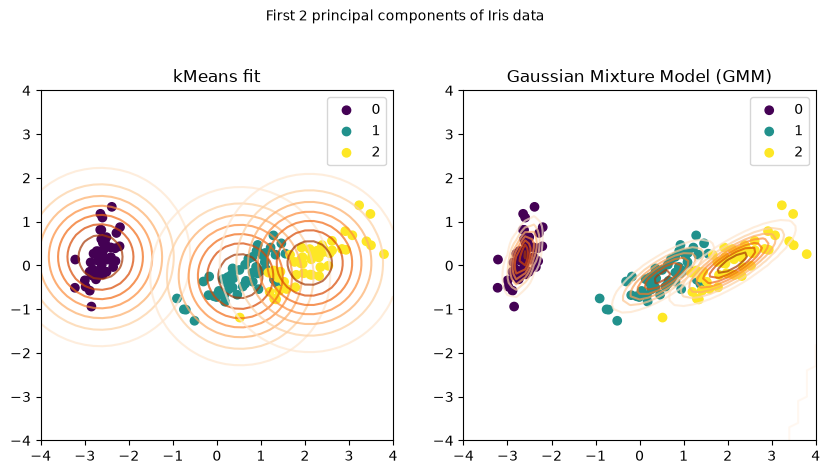

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from scipy.stats import multivariate_normal as mvn

x, y = load_iris(return_X_y=True)
# work in principal components, to plot later in the first two:
xpc = PCA().fit_transform(x)

k = 3
assert k == np.max(y) + 1

mvns = list(range(k))
for i in range(k):
    # for simplicty, take only first 2 PCs here:
    mu = np.mean(xpc[y == i][:,:2], axis=0)
    sigma = np.cov(xpc[y == i][:,:2], rowvar=False)
    mvns[i] = mvn(mean=mu, cov=sigma, allow_singular=True)

round_mvns = list(range(k))
for i in range(k):
    mu = np.mean(xpc[y == i][:,:2], axis=0)
    sigma = np.eye(2)
    round_mvns[i] = mvn(mean=mu, cov=sigma, allow_singular=True)
    
fig = plt.gcf()
fig.set_size_inches(10, 10)
ax1 = plt.subplot(221)
ax2 = plt.subplot(222, sharex=ax1, sharey=ax1)
plt.figtext(0.35, 0.95, "First 2 principal components of Iris data")
ax1.set_title("kMeans fit")
ax2.set_title("Gaussian Mixture Model (GMM)")
xs, ys = np.mgrid[-4:4.1:.2, -4:4.1:.1]
for i in range(k):
    zs = round_mvns[i].pdf(np.dstack((xs, ys)))
    ax1.contour(xs, ys, zs,
                cmap=plt.cm.Oranges, alpha=.7)
    ax1.scatter(xpc[y == i][:,0], xpc[y == i][:,1],
                c=np.ones_like(y[y == i])*i, vmin=0, vmax=k-1,
                label=str(i))
    zs = mvns[i].pdf(np.dstack((xs, ys)))
    ax2.contour(xs, ys, zs,
                cmap=plt.cm.Oranges, alpha=.7)
    ax2.scatter(xpc[y == i][:,0], xpc[y == i][:,1],
                c=np.ones_like(y[y == i])*i, vmin=0, vmax=k-1,
                label=str(i))
ax1.legend()
ax2.legend()
plt.show()

### Gaussian mixture models, unsupervised

The procedure just described is not available if no division into classes is given to us.
In that case the class is a **latent variable**: one we do not know, but which is essential to describing the model.
What we can model well are the conditional probabilities given the value of the latent variable – that is, the distribution of a single class. The distribution of the latent variable itself is harder to describe when all we have is unlabelled data.

A two-stage procedure suggests itself: first find a division into classes with k-means (often not a particularly good one, if the homoscedasticity assumption fails) and then, on the basis of that division, set up a Gaussian mixture model – that is, obtain an estimate of the latent variable.

Now, in turn, the division into classes that the mixture model lets us compute will in general differ from the one we computed with k-means beforehand. This time, though, it is plausible that the mixture model achieves the better division, since now the shapes of the clusters are taken into account as well (approximated by ellipsoids, thanks to the normality assumption).

With this improved division into classes – that is, with the improved estimate of the latent variable – we can set up a Gaussian mixture model all over again, re-estimating the covariance matrices and the centres, much as in the iteration step of the k-means algorithm.

One more observation: if, in setting up the covariance matrices, we consider only the quality of the model for a single class (the best fit for that class alone), then we ignore the effect that change of model has on the other classes – and there usually is one.
It would therefore be better to optimise all the parameters simultaneously in the iteration step, towards the target quantity – the mixture model with the best fit.

To construct a good estimator for an arbitrary distribution we have used the maximum likelihood method, and that is what we want to try for a mixture of normal distributions too.

## Maximum likelihood in models with latent variables

The probability density in the Gaussian mixture model, where $\theta_j$ denotes the parameters $\mu_j,\Sigma_j$ of a single mixture component and $p_j$ the distribution of the components, is

$$
f(x) = \sum_{j=1}^k p_j f_j(x, \theta_j) = P(X=x|M=\theta) = L(\theta),
$$

and that is the likelihood (the probability of the data, computed in our model), writing $M$ for our model and $X$ for the data. So the model assumption is now: $X$ is distributed according to $f$. Here $\theta$ is the collection of the parameters $p_j$ together with the parameters $\mu_j,\Sigma_j$ hidden inside the $f_j$. Reading this quantity as a likelihood means reading it as a function of those parameters.

A tip: if you prefer to picture $\theta$ as a list indexed by $\theta_j$, simply put $\theta_0 := (p_1,\dots,p_k)$.

If we take seriously the modelling decision to express the division of the data points into classes by probabilities, we may as well model the division itself as a random variable $Y$: $Y_i = j$ if the $i$-th data point is of class $j$ – only we do not know the variable $Y$.

Our model, formulated with the latent variable $Y$, is

$$
\begin{aligned}
P(Y = j\ |\ \theta)      =& p_j \\
P(X=x\   |\ Y=j, \theta) =& f_j(x,\ \mu_j,\Sigma_j) \\
P(X=x\   |\ \theta)      =& \sum_{j=1}^k P(X=x,\ Y=j\ |\ \theta) \\
                         =& \sum_{j=1}^k P(Y = j\ |\ \theta)\, P(X=x\ |\ Y=j, \theta).
\end{aligned}
$$

### Finding the zeros of the derivative?

Finding the zeros of the derivative of $L(\theta)$ directly is not easy, and the popular trick of maximising $\ell(\theta) = \log L(\theta)$ instead does not help much here either, because

$$
\begin{aligned}
\ell(\theta) =& \log P(X=x\ |\ \theta) \\
             =& \log \left( \sum_{j=1}^k P(X=x, Y=j\ |\ \theta)  \right) \\
             =& \log \left( \sum_{j=1}^k p_j f_j(x\ |\ \theta_j) \right)
\end{aligned}
$$

and the logarithm does not get us out of that sum business so easily.

### Jensen to the rescue!

We can lower our sights a little and work with Jensen's inequality (the logarithm is concave and $\sum_{j=1}^k p_j = 1$):

$$
\ell(\theta) \geq \sum_{j=1}^k p_j \log f_j(x\ |\ \theta_j)
$$

The charm of the expression on the right-hand side is that a $\theta$ which maximises the right-hand side cannot have a smaller left-hand side. In formulas: if we are given a $\theta^{(t)}$ and find a $\theta^{(t+1)}$ for which the right-hand side grows, then $\ell(\theta^{(t+1)}) \geq \ell(\theta^{(t)})$ as well.

Note that a fat $1 = \frac{q(j)}{q(j)}$ can also be multiplied into the expression for the contribution of a class, $p_j f_j$ – thus

$$
\begin{aligned}
\ell(\theta) =& \log \left( \sum_{j=1}^k P(X=x, Y=j\ |\ \theta) \right) \\
             =& \log \left( \sum_{j=1}^k q(j) \frac{P(X=x, Y=j\ |\ \theta)}{q(j)} \right).
\end{aligned}
$$

The point of this becomes visible once Jensen's inequality is applied, this time to the convex combination $\sum_{j=1}^k q(j) = 1$ – so from now on we assume that $q$ is a probability density:

$$
\begin{aligned}
\ell(\theta) \geq & \sum_{j=1}^k q(j) \log \left( \frac{P(X=x, Y=j\ |\ \theta)}{q(j)} \right) =: L(\theta,q) \\
                = & \sum_{j=1}^k q(j) \left( \log \left( P(X=x, Y=j\ |\ \theta \right) - \log q(j) \right) \\
                = & \sum_{j=1}^k q(j) \log P\left(X=x, Y=j\ |\ \theta\right) \qquad - \sum_{j=1}^k q(j) \log q(j) \\
                = & \sum_{j=1}^k q(j) \log P\left(X=x, Y=j\ |\ \theta\right) \qquad + H(q).
\end{aligned}
$$

So we have found a lower bound on $\ell(\theta)$ that we can write as the sum of an expression which is easier to compute and the entropy of the distribution with density $q$. Since the entropy does not depend on $\theta$, $L(\theta,q)$ can be maximised by maximising the other summand.

```{admonition} Remark
In the course *Introduction to Deep Learning* this very lower bound $L(\theta,q)$ is called the *ELBO* (evidence lower bound; the *evidence* is $P(X=x\ |\ \theta)$). There it is the training objective of *variational autoencoders*, in which the distribution $q$ of the latent variable is output by a neural network.
```

We shall come back to this observation (which is why we have given it a name, $L(\theta,q)$); for the moment, let us discuss a general approach to the solution.

## Auxiliary Functions

If we cannot maximise a function $\ell(\theta)$,
we can try a stopgap: pretend that $\theta$ is constant in some of the subexpressions of $\ell(\theta)$ and maximise, then hold the other subexpressions constant instead and maximise over the rest. To formalise this we introduce an auxiliary function $Q(\theta,\vartheta)$ that is easier to maximise in $\theta$ than $\ell$ is, but nevertheless satisfies $Q(\theta, \theta) = \ell(\theta)$ and, moreover, $Q(\theta,\vartheta) \leq \ell(\theta)$ for all $\vartheta$.

These assumptions are already enough to show that an iterative process leads to better and better approximations $\theta^{(t)}$ to the $\theta$ that maximises $\ell(\theta)$. Here $\theta^{(t+1)}$ denotes the $\theta$ that makes $Q(\theta, \theta^{(t)})$ maximal (which by assumption is easy to find).

$$
\begin{aligned}
\ell(\theta^{(t)}) =& Q(\theta^{(t)}, \theta^{(t)}) \\
               \leq & Q(\theta^{(t+1)}, \theta^{(t)}) \text{ (M-step)} \\
               \leq & Q(\theta^{(t+1)}, \theta^{(t+1)}) \text{ (E-step)} \\
                    &  = \ell(\theta^{(t+1)}).
\end{aligned}
$$

All told, $\ell(\theta^{(t)}) \leq \ell(\theta^{(t+1)})$ – which is to say that at least our estimate never gets worse along the way!

If we want to take this approach, what remains is to choose a well-judged auxiliary function $Q(\theta,\vartheta)$.


## The complete-data log-likelihood

The last ingredient for developing the EM algorithm for the Gaussian mixture model is the complete-data log-likelihood: the log-likelihood in the fictitious world in which we really do know the complete data – not only the values of $X$ but those of the latent variable $Y$ as well, that is, the actual classes of the data points.

The complete data are therefore the $(x_i,y_i)$, which we model with $(X,Y)$.

It is useful now to look at the variable $Y_i$ in one-hot encoding as well: $Y_{ij} = 1$ if $Y_i = j$, and $Y_{ij} = 0$ if $Y_i \neq j$. Some people write $[Y_i=j]$ for this (the Iverson bracket).

The log-likelihood of the data under the Gaussian mixture model is

$$
\begin{aligned}
\ell_c(\theta) = \log P((X,Y)|\theta) =& \sum_{i=1}^n \log P(X=x_i, Y=y_i\ |\ \theta) \\
                                       & \sum_{i=1}^n \log \prod_{j=1}^k {P(X=x_i, Y=j\ |\ \theta)}^{Y_{ij}} \\
                                       & \sum_{i=1}^n \sum_{j=1}^k Y_{ij} \log P(X=x_i, Y=j\ |\ \theta)
\end{aligned}
$$

where in the first step we inserted a fat $1$: $Y_{ij}$ is $1$ for just one factor of the product $\prod_{j=1}^k (...)^{Y_{ij}}$ and $0$ otherwise, which makes the corresponding factor $1$.
The second step is just $\log \prod (...)^t = \sum t \log (...)$.

Note also that $\theta$ is now really only $\theta_1,\dots,\theta_k$, since the $p_i$ are encoded in the distribution of $Y$.

We can simplify further:

$$
\log P(X=x_i, Y=y_i) = \log \left( p_{y_i} f_{y_i}(x_i) \right) = \log p_{y_i} + \log f_{y_i}(x_i)
$$

### The expected value over the latent variable

If we assume a distribution $q(y)$ for the latent variable $Y$, then we can take the expected value over it:

$$
\begin{aligned}
\mathbb{E}_{Y \sim q} \ell_c(\theta) =& \mathbb{E}_{Y \sim q} \left( \sum_{i=1}^n \sum_{j=1}^k Y_{ij} \left( \log p_{y_i} + \log f_{y_i}(x_i\ |\ \theta_{y_i}) \right) \right) \\
 =& \sum_{i=1}^n \sum_{j=1}^k \mathbb{E}_{Y \sim q} Y_{ij} \left( \log p_{j} + \log f_{j}(x_i\ |\ \theta_j) \right) \\
 =& \sum_{i=1}^n \sum_{j=1}^k \tau_{ij} \left( \log p_{j} + \log f_{j}(x_i\ |\ \theta_j) \right).
\end{aligned}
$$

The terms denoted $\tau_{ij}$ we call the **responsibilities**, since in our model they are responsible for the division of the points $x_i$ into classes:

$$
\tau_{ij} := \mathbb{E}_{Y \sim q} Y_{ij} = P(Y_i = j\ |\ X=x_i,\theta) = \frac{P(Y_i = j,\ X=x_i\ |\ \theta)}{P(X=x_i\ |\ \theta)}
$$

If we hold the $\tau_{ij}$ fixed, then $\mathbb{E}_{Y \sim q} \ell_c(\theta)$ is a quantity we can maximise (even though the $\tau_{ij}$ do of course really depend on $\theta$). We still want to regard the $\tau_{ij}$ as a function of $\theta$, but from now on we call that argument $\vartheta$.

So we define

$$
Q(\theta,\vartheta) := \sum_{i=1}^n \sum_{j=1}^k \tau_{ij}(\vartheta) \left( \log p_{j} + \log f_{j}(x_i\ |\ \theta_j) \right)
$$

For $\theta=\vartheta$ this is the expected complete-data log-likelihood under our assumption $q$ about the distribution of the latent variable $Y$.
Note, too, that the other term, $\log P(X=x_i, Y=j) = \left( \log p_{j} + \log f_{j}(x_i\ |\ \theta_j) \right)$, depends on $\theta$, not on $\vartheta$.

### The difference between L(θ, q) and Q(θ, θ)

Let us recall the observation we reached with the help of Jensen's inequality:

$$
\ell(\theta) \geq L(\theta, q) = \sum_{j=1}^k q(j) \log P\left(X=x, Y=j\ |\ \theta\right) \qquad + H(q)
$$

and note that the summand other than $H(q)$ is exactly the expected complete-data log-likelihood, that is

$$
\ell(\theta) \geq L(\theta, q) = \mathbb{E}_{Y \sim q} \ell_c(\theta) + H(q) = Q(\theta,\theta) + H(q)
$$

Since $H(q)$ does not depend on $\theta$, maximising $Q(\theta,\vartheta)$ in $\theta$ therefore also maximises $L(\theta, q)$ in $\theta$.

### The difference between ℓ(θ) and L(θ, q)

Let us rearrange the formula for $L(\theta, q)$ once more, in a different way: we express the joint distribution $P(X=x, Y=j)$ through conditional distributions, $P(Y=j, X=x) = P(Y=j|X=x)P(X=x)$, and obtain:

$$
\begin{aligned}
\ell(\theta) \geq& L(\theta, q) = \sum_{j=1}^k q(j) \log \left( \frac{P(X=x, Y=j\ |\ \theta)}{q(j)} \right) \\
                 & = \sum_{j=1}^k q(j) \log \left( \frac{ P(Y=j\ |\ X=x, \theta) P(X=x\ |\ \theta) }{q(j)} \right) \\
                 & = \sum_{j=1}^k q(j) \log \left( \frac{P(Y=j\ |\ X=x, \theta)}{q(j)} \right) \qquad + \sum_{j=1}^k q(j) \log\left( P(X=x\ |\ \theta) \right) \\
                 & = -H\big(q \,\Vert\, P(Y \mid X=x, \theta)\big) + \ell(\theta).
\end{aligned}
$$

The difference between $\ell(\theta)$ and $L(\theta,q)$ is therefore exactly the relative entropy of the estimated distribution $q$ to the actual distribution $P(Y \mid X=x, \theta)$ (in the notation of the chapter [Relative entropy](relative-entropy.md)):

$$
\ell(\theta) - L(\theta, q) = H\big(q \,\Vert\, P(Y \mid X=x, \theta)\big)
$$

With that we also have $\ell(\theta) - Q(\theta,\theta) = H\big(q \,\Vert\, P(Y \mid X=x, \theta)\big) + H(q)$, so we now understand exactly in what sense $\ell(\theta)$ can be maximised by way of $Q(\theta,\theta)$.

## The EM algorithm for fitting a Gaussian mixture model

The algorithm is initialised with a choice of $\theta^{(0)}$ (and, as we have already seen with k-means, the result generally depends very much on this initialisation). One possible choice for the $\mu_j$ (the cluster centres) is to run the k-means algorithm (with k-means++ initialisation) on the data and take the converged centroids as the $\mu_j$. For the covariance matrices one can start with identity matrices (which corresponds to a shifted standard normal distribution). The mixing ratio, that is the $p_i$, can be initialised to $p_i = \frac{1}{k}$.

Then the E-step and the M-step are carried out iteratively, alternating between the two:

* **E-step**: update the parameter $\vartheta$: set $\vartheta = \theta$ and compute the responsibilities $\tau_{ij} := \tau_{ij}(\theta)$, so as to have a correct formula for $Q(\theta,\theta)$ again – or rather a new estimate of $q$, and with it of $L(\theta, q)$. In this step we estimate the latent variable, aiming to minimise the relative entropy to its actual distribution (that is, to approximate it as well as possible). The better the estimate, the closer $L(\theta, q)$ lies to $\ell(\theta)$.
* **M-step**: update the parameter $\theta$: maximise the expected complete log-likelihood $Q(\theta,\vartheta)$ in $\theta$ (with $\vartheta$ held fixed, so that the responsibilities $\tau_{ij}$ are constant). This maximises $L(\theta, q)$, a lower bound on $\ell(\theta)$.

The procedure converges, since the approximations to a maximum of $\ell(\theta)$ never get worse (because of Jensen's inequality, one might say).

So far we have not needed to know what form the density functions $f_j$ take – in fact everything discussed up to this point works for arbitrary distributions as well! With some care, the latent variable may even be continuous, as long as the sums from $j=1$ to $k$ are suitably replaced by the corresponding integrals. Seen that way, the EM algorithm is really not one algorithm but a template for developing many concrete EM algorithms.

More generally still, when the aim is not necessarily to maximise a likelihood in the presence of latent variables, one speaks of MM algorithms – for minorise–maximise (or, for minimisation problems, majorise–minimise) – and of optimisation transfer; a good introduction is Hunter & Lange, *A Tutorial on MM Algorithms*, The American Statistician 58 (2004). With these keywords you can track down the literature should you need a generalisation of the EM algorithm.

For the moment, though, we restrict ourselves to a discrete, finite latent variable $Y$ and head towards an implementation in Python.

### Concrete formulas for the Gaussian mixture model

To implement the algorithm concretely we must of course use concrete density functions too, and that is what we do now – so let us recall that the multivariate normal distribution has this density:

$$
f_j(x) = f_j(x, \mu_j, \Sigma_j) = \dfrac{1}{\sqrt{(2\pi)^n \det\Sigma_j}} e^{-\frac{(x-\mu_j)^T \Sigma_j^{-1} (x - \mu_j)}{2}}.
$$

To make life easy for ourselves, we look at the univariate case first, so that

$$
f_j(x) = f_j(x, \mu_j, \sigma_j) = \dfrac{1}{\sqrt{2\pi}\,\sigma_j}\, e^{-\frac{(x-\mu_j)^2}{2\sigma_j^2}}.
$$

At step $t$ of the iteration we are given the parameters $\theta^{(t)}$, that is, $\mu_j^{(t)}$ and $\Sigma_j^{(t)}$ together with the mixture parameters $p_j^{(t)}$. The superscript index $t$ counts the iterations; $i$ remains the sample index, as in $x_i$.

In the E-step we compute the responsibilities

$$
\begin{aligned}
\tau_{ij}(\theta^{(t)}) =& \frac{P(Y_i = j, X=x_i\ |\ \theta)}{P(X=x_i\ |\ \theta)} \\
                        =& \frac{P(Y_i = j, X=x_i\ |\ \theta)}{\sum_{m=1}^k P(Y_i = m, X=x_i\ |\ \theta)}  \\
                        =& \frac{p_j^{(t)} f_j\left(x_i,\mu_j^{(t)},\sigma_j^{(t)}\right)}{\sum_{m=1}^k p_m^{(t)} f_m\left(x_i,\mu_m^{(t)},\sigma_m^{(t)}\right).}
\end{aligned}
$$

In the M-step we maximise $Q(\theta,\vartheta)$ in $\theta$ by finding the zeros of the derivative with respect to $\theta$, that is, we solve the system of equations

$$
\begin{aligned}
0 =& \frac{d}{d\theta} Q(\theta, \vartheta) \\
  =& \frac{d}{d\theta} \sum_{i=1}^n \sum_{j=1}^k \tau_{ij}(\vartheta) \left( \log p_{j} + \log f_{j}(x_i\ |\ \theta_j) \right) \\
  =& \sum_{i=1}^n \sum_{j=1}^k \tau_{ij}(\vartheta)\frac{d}{d\theta} \left( \log p_{j} + \log f_{j}(x_i\ |\ \theta_j) \right).
\end{aligned}
$$

First we look at the derivatives with respect to the $\mu_j$:

$$
\begin{aligned}
\frac{d}{d\mu_j} \log f_j(x_i) =& - \frac{\frac{d}{d\mu_j}(x_i-\mu_j)^2}{2\sigma_j^2} = \frac{x_i-\mu_j}{\sigma_j^2} \\
\frac{d}{d\mu_j} Q(\theta, \theta^{(t)}) =& \sum_{i=1}^n \sum_{j=1}^k \tau_{ij}(\vartheta) \frac{d}{d\mu_j} \log f_{j}(x_i\ |\ \theta_j) \\
 =& \sum_{i=1}^n \tau_{ij}(\vartheta) \frac{x_i-\mu_j}{\sigma_j^2}.
\end{aligned}
$$

Multiplying through by $\sigma_j^2$ and solving for $\mu_j$ gives the closed formula

$$
\mu_j^{(t+1)} = \frac{\sum_{i=1}^n \tau_{ij} x_i }{ \sum_{i=1}^n \tau_{ij}}.
$$

Next we look at the derivatives with respect to the $\sigma_j$:

$$
\begin{aligned}
\frac{d}{d\sigma_j} \log f_j(x_i) =& -\frac{1}{\sigma_j} + \frac{(x_i-\mu_j)^2}{\sigma_j^3} \\
\frac{d}{d\sigma_j} Q(\theta, \theta^{(t)}) =& \sum_{i=1}^n \tau_{ij} \left( \frac{(x_i-\mu_j)^2}{\sigma_j^3} -\frac{1}{\sigma_j} \right).
\end{aligned}
$$

Solving the equation $0 = \frac{d}{d\sigma_j} Q(\theta, \theta^{(t)})$ for $\sigma_j$ (multiplying through by $\sigma_j^3$) gives

$${\left(\sigma_j^{(t+1)}\right)}^2 = \frac{\sum_{i=1}^n \tau_{ij}(x_i-\mu_j)^2}{\sum_{i=1}^n \tau_{ij}}$$

Finally, in the same way, the zeros of the derivative with respect to $p_j$ give the formula that represents $p_j$ as the responsibility of $x_i$ for class $j$, averaged over the $x_i$:

$$
p_j^{(t+1)} = \frac{\sum_{i=1}^n \tau_{ij}}{n}
$$

With that, the new parameters $\theta^{(t+1)}$ have been found.

#### Special case: k-means

If we hold $p_j = \frac{1}{k}$ and $\Sigma_j = E_d$ fixed, we obtain the formulas

$$
\tau_{ij}(\theta^{(t)}) = \frac{f_j\left(x_i,\mu_j^{(t)},E_d\right)}{\sum_{m=1}^k f_m\left(x_i,\mu_m^{(t)},E_d\right)}
$$

A real difference from the classical k-means algorithm is that here we have worked with **soft assignments**: for every possible class of a point $x_i$ we have determined a probability $\tau_{ij}$. Classical k-means, by contrast, commits itself – it makes a **hard assignment**. We can just as well set $\widetilde{\tau_{ij}} := 1$ when $\tau_{ij}$ is the largest of all the $\tau_{im}$, and $\widetilde{\tau_{ij}} := 0$ otherwise. With that we get

$$
\begin{aligned}
\mu_j^{(t+1)} =& \frac{\sum_{i=1}^n \widetilde{\tau_{ij}} x_i }{ \sum_{i=1}^n \widetilde{\tau_{ij}}} \\
              =& \frac{1}{n_j} \sum_{i:\ y_i = j} x_i, \qquad n_j := \sum_{i=1}^n \widetilde{\tau_{ij}} = \big|\{ i : y_i = j \}\big|,
\end{aligned}
$$

where $y_i$ is the class to which $x_i$ was hard-assigned. That is exactly the arithmetic mean of the $n_j$ points $x_i$ in class $j$. With the soft assignment instead, it is a weighted mean of the $x_i$ that gives less weight to the points whose assignment is less certain – another obvious improvement on classical k-means.

#### Implementing more general models

If you want to implement models more general than the ones discussed here, you have to adapt the part in which the explicit closed formulas for $p_j$, $\mu_j$, $\sigma_j$ are computed. We were able to find closed formulas because the $\log$ of a density that can be written as $e^{(...)}$ is especially simple. As a rule of thumb, then, every distribution of that same build can be treated the same way and used in place of the normal distribution. The precise statement is that every distribution from a so-called exponential family is suitable.

### Implementation in Python

#### Univariate data

In [2]:
# version for univariate Gaussian mixtures,
# not vectorised (for the sake of understanding)

from scipy.stats import norm

def EM(xs, pis, mus, sigmas):
    K = len(pis)
    N = xs.shape[0]
    
    #(E) step
    taus = np.zeros((N,K))
    for i in range(N):
        reg = 0
        for j in range(K):
            taus[i,j] = pis[j] * norm.pdf(xs[i],
                                          loc=mus[j],
                                          scale=sigmas[j])
            reg += taus[i,j]
        for j in range(K):
            taus[i,j] /= reg
    
    #(M) step
    Npis = np.zeros(K)
    for j in range(K):
        Npis[j] = taus[:,j].sum()
    pis = Npis / N

    mus = np.zeros(K)
    for j in range(K):
        for i in range(N):
            mus[j] += taus[i, j] * xs[i]
        mus[j] /= Npis[j]

    sigmas = np.zeros(K)
    for j in range(K):
        for i in range(N):
            sigmas[j] += taus[i, j] * ((xs[i]- mus[j])**2)
        sigmas[j] /= Npis[j]
        sigmas[j] = np.sqrt(sigmas[j])
    
    ll_new = 0.0
    for i in range(N):
        s = 0
        for j in range(K):
            s += pis[j] * norm.pdf(xs[i],
                                   loc=mus[j],
                                   scale=sigmas[j])
        # compute new log-likelihood:
        ll_new += np.log(s)
        
    return pis, mus, sigmas, taus, ll_new

As with the k-means algorithm, we now want to watch the fit improve over the course of the iteration. First we knock together some test data:

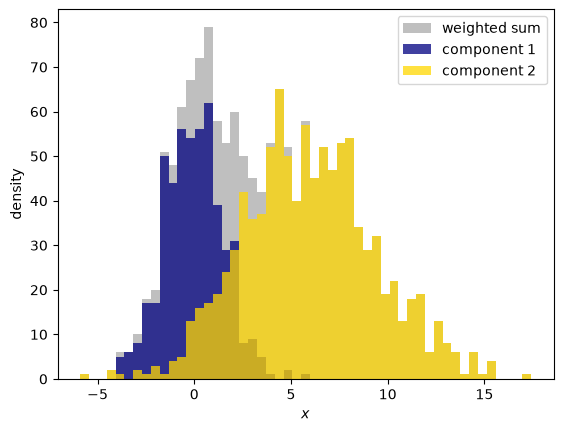

In [3]:
np.random.seed(12345)
pi = 1.0/3
real_mu_1, real_sigma_1 = 0, 1.5
real_mu_2, real_sigma_2 = 6, 3.5
component1_sample = norm.rvs(real_mu_1,
                             real_sigma_1,
                             int(pi*1500))
component2_sample = norm.rvs(real_mu_2,
                             real_sigma_2,
                             int((1-pi)*1500))
mixture_samples = np.concatenate((component1_sample,
                                  component2_sample))

fig, ax = plt.subplots()
hist = ax.hist(mixture_samples, bins=51,
               color='grey', alpha=.5,
              label="weighted sum")
bins = hist[1]
ax.hist(component1_sample, alpha=.75, bins=bins,
       color='navy', label="component 1")
ax.hist(component2_sample, alpha=.75, bins=bins,
       color='gold', label="component 2")
ax.set_xlabel("$x$")
ax.set_ylabel("density")
ax.legend()
plt.show()

In [4]:
# set up the initial theta:
pis =  np.ones(2) + np.random.random(2)
pis /= pis.sum()
mus =  np.random.random(2) * 2*np.std(mixture_samples)\
       + np.mean(mixture_samples)
sigmas =  np.sqrt(np.random.random(2) + 1)

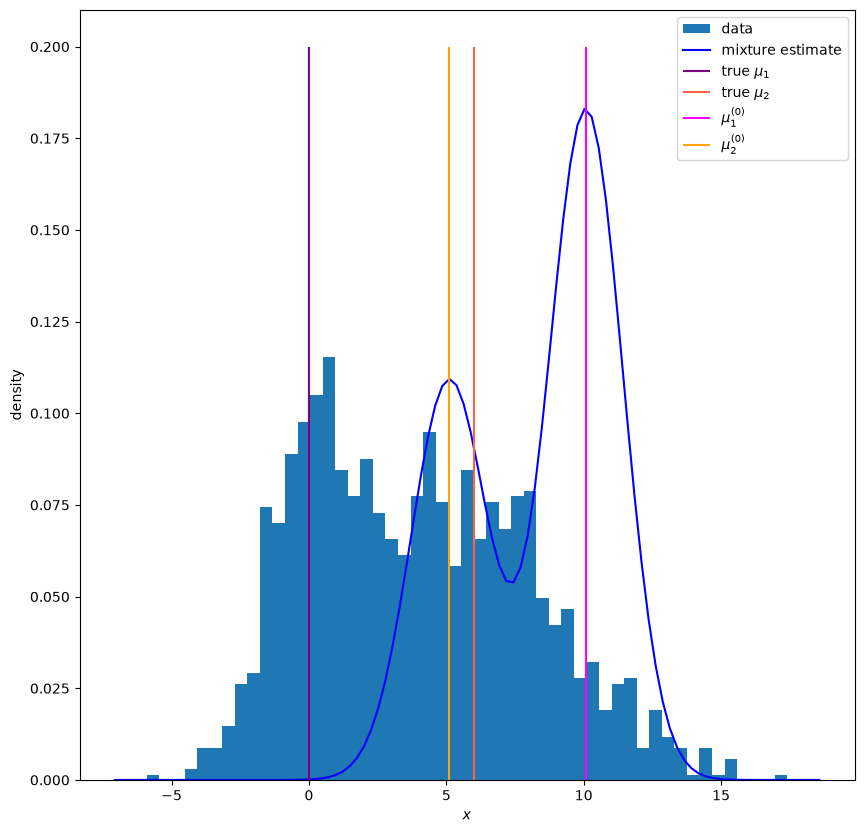

In [5]:
# the true parameters vs. the initial ones:
fig, ax = plt.subplots(figsize=(10,10))
hist = ax.hist(mixture_samples, bins=51,
               density=True,
               label="data")
xmin, xmax = ax.get_xlim()
norm_pdf_domain = np.linspace(xmin, xmax, 100)
ax.plot(norm_pdf_domain,
         pis[0]*norm.pdf(norm_pdf_domain,
                         mus[0], sigmas[0]) +
         pis[1]*norm.pdf(norm_pdf_domain,
                         mus[1], sigmas[1]),
         color='blue',
         label="mixture estimate")
ax.vlines(real_mu_1, 0, .2,
          color='purple', label='true $\\mu_1$')
ax.vlines(real_mu_2, 0, .2,
          color='tomato', label='true $\\mu_2$')
ax.vlines(mus[0], 0, .2,
          color='fuchsia', label='$\\mu_1^{(0)}$')
ax.vlines(mus[1], 0, .2,
          color='orange', label='$\\mu_2^{(0)}$')
ax.set_xlabel("$x$")
ax.set_ylabel("density")
ax.legend()
plt.show()

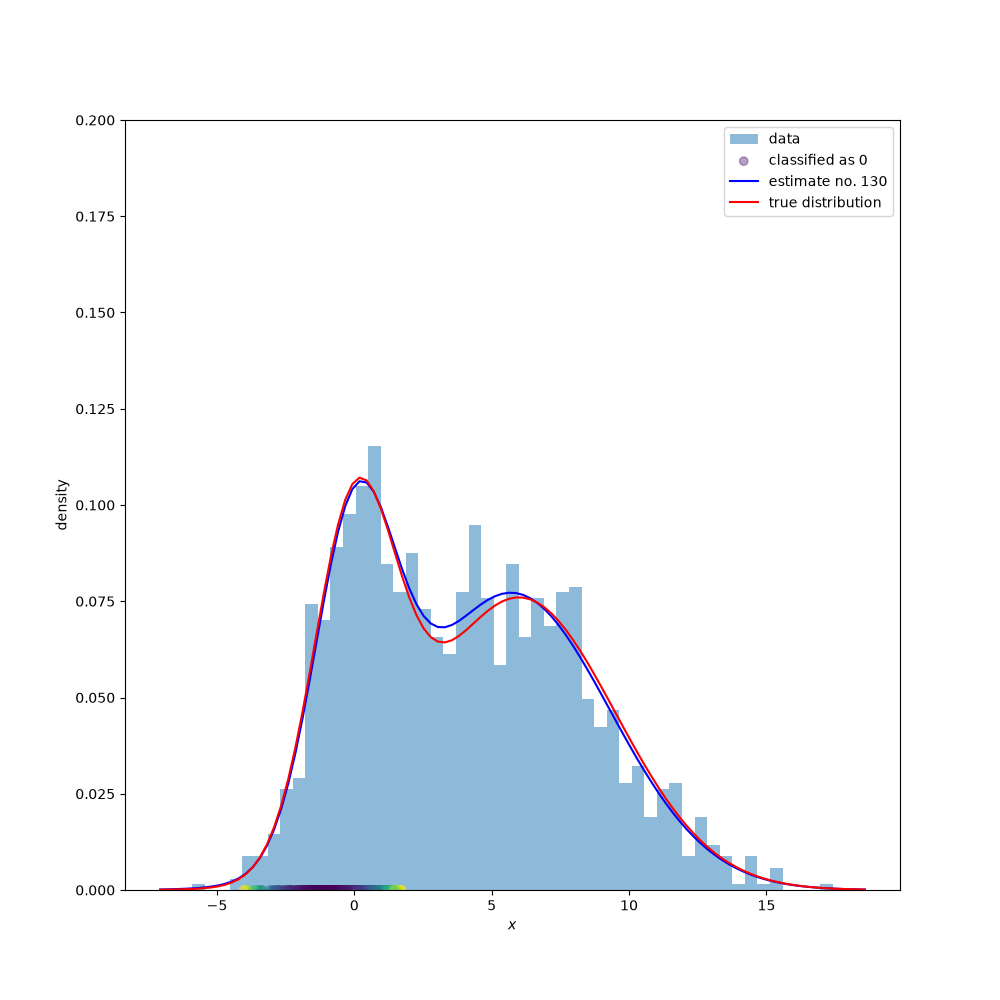

In [6]:
import matplotlib.animation as animation
from IPython import display as ipydisplay
import io, base64
from sklearn.cluster import KMeans

def init_theta(samples):
    pis = np.ones(2) / 2
    mus = np.random.random(2) * 2*np.std(samples)\
          + np.mean(samples)
    # a better way would be:
    #mus = KMeans(2).fit(samples.reshape(-1,1)).cluster_centers_
    sigmas =  np.ones(2)
    return pis, mus, sigmas

def em_iteration_draw(run_nr, ax, samples, history):
    pis, mus, sigmas, taus = history[run_nr][0:4]
    ys = np.zeros_like(samples, dtype=bool)
    if(len(taus) == len(samples)):
        for i in range(len(samples)):
            if(taus[i,1] > 0.5):
                ys[i] = 1
    ax.clear()
    ax.set_ylim(0, 0.2)
    ax.hist(samples, bins=51,
            density=True, alpha=0.5,
            label="data")
    if(len(taus) == len(samples)):
        ax.scatter(samples[ys], np.zeros_like(samples[ys]),
                   alpha=0.4, c=taus[ys][:,0],
                   label="classified as 0")
    xmin, xmax = ax.get_xlim()
    norm_pdf_domain = np.linspace(xmin, xmax, 100)
    ax.plot(norm_pdf_domain,
            pis[0]*norm.pdf(norm_pdf_domain,
                            mus[0], sigmas[0]) +
            pis[1]*norm.pdf(norm_pdf_domain,
                            mus[1], sigmas[1]),
            color='blue',
            label="estimate no. %d" % (run_nr))
    ax.plot(norm_pdf_domain,
            pi    *norm.pdf(norm_pdf_domain,
                            real_mu_1, real_sigma_1) +
            (1-pi)*norm.pdf(norm_pdf_domain,
                            real_mu_2, real_sigma_2),
            color='red',
            label="true distribution")
    ax.set_xlabel("$x$")
    ax.set_ylabel("density")
    ax.legend()
    
def plot_ani(samples, history):
    fig, ax = plt.subplots(figsize=(10, 10))
    ani = animation.FuncAnimation(fig, em_iteration_draw,
                                  fargs=(ax, samples, history),
                                  interval=1000,
                                  frames=len(history))
    video = ani.to_html5_video()
    # Output the last frame as a PNG as well: the web export shows the video,
    # the PDF export (which cannot do HTML) uses the still image.
    png = io.BytesIO()
    fig.savefig(png, format='png')
    ipydisplay.display({'text/html': video,
                        'image/png': base64.b64encode(png.getvalue()).decode('ascii')},
                       raw=True)
    plt.close()


max_iter = 210
tol = 0.01
pis, mus, sigmas = init_theta(mixture_samples)
taus = np.zeros((len(mixture_samples), len(pis)))
# record all values in each iteration step for plotting:
history = [(pis, mus, sigmas, taus, 0)]

for i in range(max_iter):
    pis, mus, sigmas = history[-1][0:3]
    history += [EM(mixture_samples,
                   pis,
                   mus,
                   sigmas)]
    if np.abs(history[-1][-1] - history[-2][-1]) < tol:
        break
        
plot_ani(mixture_samples, history)

#### Multivariate data

For the more general multivariate case we shall not labour through the derivation again, but go straight to the corresponding code:

In [7]:
from scipy.stats import multivariate_normal as mvn

def EMmulti(xs, pis, mus, sigmas, tol=0.01, max_iter=100):
    """vectorized E-M for multivariate Gaussian mixtures"""

    n, d = xs.shape
    k = len(pis)

    ll_old = 0.0
    for i in range(max_iter):

        # (E) step
        taus = np.zeros((k, n))
        for j in range(k):
            taus[j, :] = pis[j] * mvn(mus[j], sigmas[j]).pdf(xs)
        taus /= taus.sum(axis=0)

        # (M) step
        pis = taus.sum(axis=1)
        pis /= n

        mus = np.dot(taus, xs)
        mus /= taus.sum(axis=1)[:, None]

        sigmas = np.zeros((k, d, d))
        for j in range(k):
            xcs = xs - mus[j, :]
            sigmas[j] = (taus[j,:,None,None]\
                         * np.matmul(xcs[:,:,None],
                                     xcs[:,None,:])).sum(axis=0)
        sigmas /= taus.sum(axis=1)[:,None,None]

        ll_new = 0.0
        for pi, mu, sigma in zip(pis, mus, sigmas):
            ll_new += pi * mvn(mu, sigma).pdf(xs)
        ll_new = np.log(ll_new).sum()

        if np.abs(ll_new - ll_old) < tol:
            break
        ll_old = ll_new

    return ll_new, pis, mus, sigmas

## Example applications

### Whereabouts

`data.csv` contains a record of whereabouts. The data come, under the MIT licence, from [a blog post](https://towardsdatascience.com/simple-gps-data-visualization-using-python-and-open-street-maps-50f992e9b676)
which explains how to embed OpenStreetMaps – though that is not needed here.

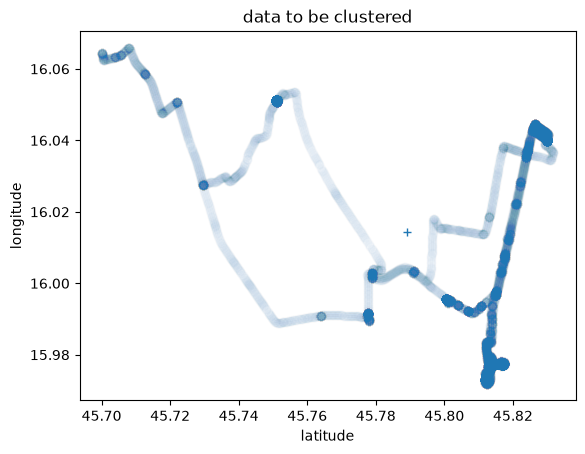

In [8]:
data = np.genfromtxt("data.csv", delimiter=',')
fig, ax = plt.subplots()
ax.scatter(data[:,0], data[:,1], alpha=0.01)
ax.set_title("data to be clustered")
ax.set_xlabel("latitude")
ax.set_ylabel("longitude")
ax.plot(np.mean(data[:,0]), np.mean(data[:,1]), marker="+")
plt.show()

The transformation to principal components is of little use with these data:

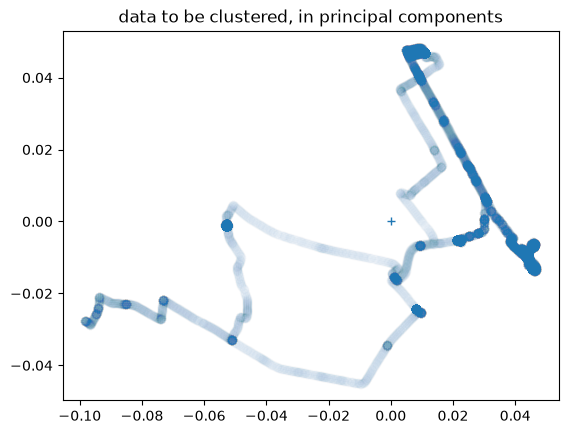

In [9]:
from sklearn.decomposition import PCA

pc = PCA().fit_transform(data)
fig, ax = plt.subplots()
ax.scatter(pc[:,0], pc[:,1], alpha=0.01)
ax.set_title("data to be clustered, in principal components")
ax.plot(np.mean(pc[:,0]), np.mean(pc[:,1]), marker="+")
plt.show()

In [10]:
np.random.seed(1234321)
pis = np.array([0.2,0.2,0.2,0.2,0.2])
mus = np.random.random((5,2)) + np.mean(data)
sigmas = np.array([np.eye(2)] * 5)
ll_new, pis, mus, sigmas = EMmulti(data, pis, mus, sigmas)

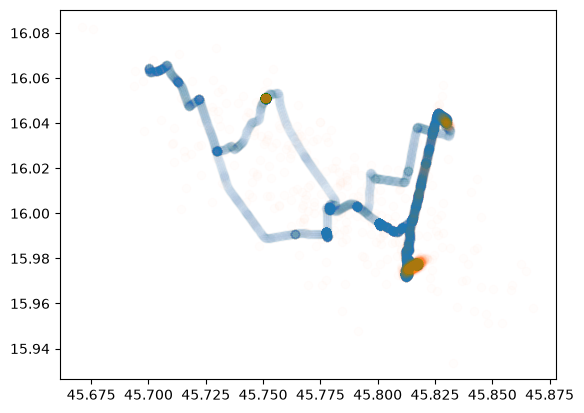

In [11]:
ys = np.concatenate([mvn(m, s).rvs(int(p*2000))
                    for p, m, s in zip(pis, mus, sigmas)])

fig, ax = plt.subplots()
ax.scatter(data[:,0],data[:,1],alpha=0.01)
ax.scatter(ys[:,0],ys[:,1],alpha=0.01)
plt.show()

One interpretation would be that we have now identified the places where the longer stays happened.

### Iris classification

We now use scikit-learn's GMM (Gaussian mixture model) implementation to model the Iris dataset.


In [12]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_iris
x, y = load_iris(return_X_y=True)
k=3

# transform to principal components for plotting:
xpc = PCA().fit_transform(x)

# fit with the EM algorithm:
gm = GaussianMixture(n_components=k,
                     random_state=42,
                     max_iter=100,
                     init_params='k-means++',
                     verbose=1).fit(xpc)
if(gm.converged_):
    print("converged after %d steps" % gm.n_iter_)
else:
    print("could not reach convergence")

Initialization 0
  Iteration 10
Initialization converged.
converged after 19 steps


From the Gaussian mixture model we can also obtain the individual probabilities:

In [13]:
y_pred = gm.predict(xpc)
y_pred_proba = gm.predict_proba(xpc)
y_pred_maxproba = np.max(y_pred_proba,
                         axis = 1)

Here we look for the permutation that agrees best with the actual classes:

In [14]:
from itertools import permutations
best_accuracy = 0.0
for permutation in permutations(range(k)):
    y_pred_permuted = np.array([permutation[value]
                                for value in y_pred])
    this_accuracy = accuracy_score(y_pred_permuted, y)
    if(this_accuracy > best_accuracy):
        best_accuracy = this_accuracy
        y_pred_bestperm = y_pred_permuted

print("Accuracy: %2.f%%" % (100*best_accuracy))

Accuracy: 97%


And finally we plot what the result looks like:

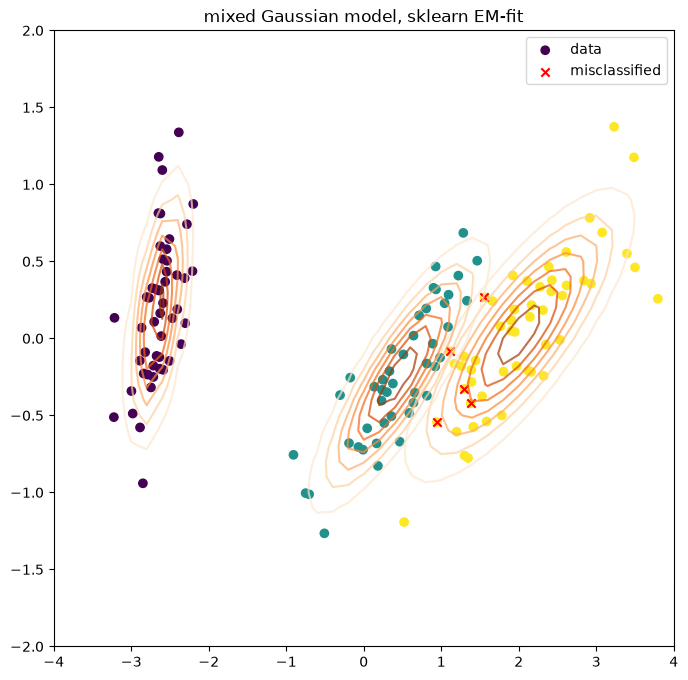

In [15]:
    
# we look directly at the marginal distributions
# in the first 2 principal components:
mvns = [mvn(mean=mu[:2],
            cov=sigma[:2,:2],
            allow_singular=True)
        for mu, sigma in zip(gm.means_,
                             gm.covariances_)]

x_wrongs = xpc[y_pred_bestperm != y]

fig, ax = plt.subplots(figsize=(8,8))
ax.set_title("mixed Gaussian model, sklearn EM-fit")
xs, ys = np.mgrid[-4:4.1:.2, -2:2.1:.1]
for i in range(k):
    zs = mvns[i].pdf(np.dstack((xs, ys)))
    ax.contour(xs, ys, zs,
               cmap=plt.cm.Oranges, alpha=.7)
ax.scatter(xpc[:,0], xpc[:,1],
           c=y_pred_bestperm, vmin=0, vmax=k-1,
           label='data')
ax.scatter(x_wrongs[:,0], x_wrongs[:,1],
           c='red', marker='x',
           label='misclassified')
ax.legend()
plt.show()

### Handwritten digits

On the UCI ML hand-written digits dataset we look at how well such a GMM works and how it can be used generatively, to produce new samples of a class.

In [16]:
from sklearn.datasets import load_digits
x,y = load_digits(return_X_y=True)
vargoal = .95 # keep so much of variance
pca = PCA(vargoal)
pca.fit(x)
print("kept %d of %d dimensions for %2.f%% of variance "
      % (len(pca.components_), x.shape[1], 100*vargoal))
data = pca.transform(x)

kept 29 of 64 dimensions for 95% of variance 


:::{note}
**Looking ahead (not part of the course proper):** the Bayesian information criterion in this section is one of several ways of choosing the number of components, and is not needed in the course.
:::

How many components should the model have? In the chapter on model selection we met tools for questions of this kind. For mixture models the **Bayesian information criterion** (BIC) is in common use: $\mathrm{BIC} = -2 \log L + m \log n$, with the log-likelihood $\log L$, the number $m$ of model parameters and the sample size $n$. Every additional component increases $m$ and has to earn that back first through a better likelihood. One picks the $k$ with the smallest BIC:

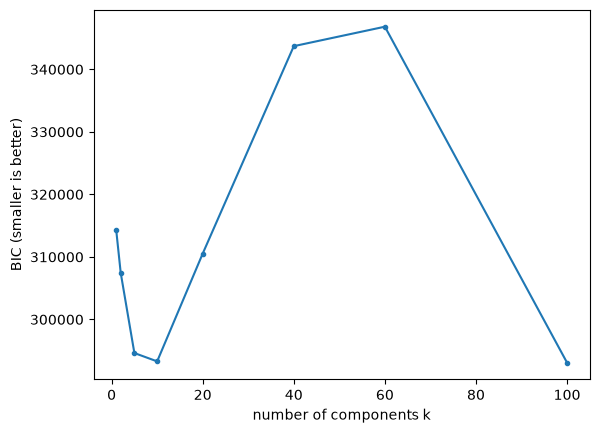

smallest BIC at k = 100


In [17]:
ks = [1, 2, 5, 10, 20, 40, 60, 100]
bics = [GaussianMixture(k, random_state=23).fit(data).bic(data) for k in ks]

fig, ax = plt.subplots()
ax.plot(ks, bics, marker=".")
ax.set_xlabel("number of components k")
ax.set_ylabel("BIC (smaller is better)")
plt.show()
print("smallest BIC at k =", ks[np.argmin(bics)])

Here the BIC keeps falling right up to the largest $k$ tested: the digits evidently break up into very many small clusters (different ways of writing the same digit), and anyone who wants to find the minimum has to extend the range. In what follows we nevertheless try out various $k$ by hand, to see what the individual components learn.

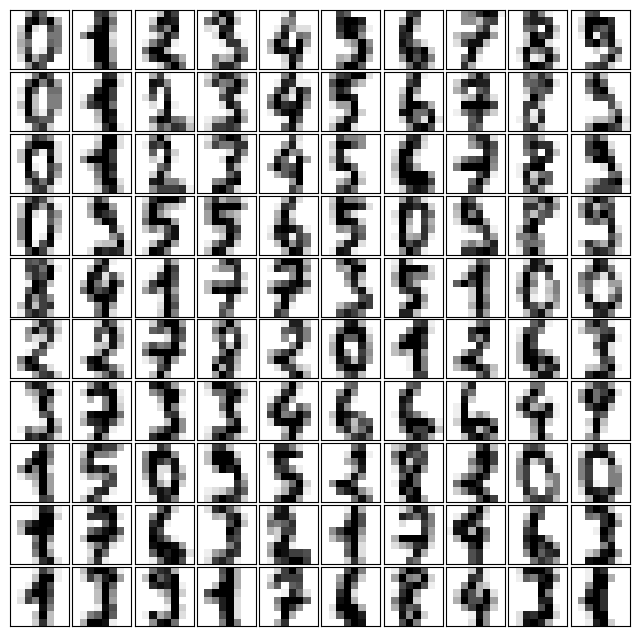

In [18]:
def plot_digits(x):
    so_many_rows = min(100, len(x)) // 10
    fig, ax = plt.subplots(so_many_rows, 10, figsize=(8, 8),
    subplot_kw=dict(xticks=[], yticks=[]))
    fig.subplots_adjust(hspace=0.05, wspace=0.05)
    for i, axi in enumerate(ax.flat):
        im = axi.imshow(x[i].reshape(8, 8), cmap='binary')
        #im.set_clim(0, 16)
    plt.show()

plot_digits(x)

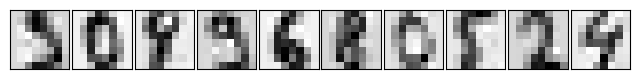

[ 1 15 24 49 57 60 62 65 68 99]


In [19]:
gm = GaussianMixture(100, random_state=23)
gm.fit(data)

new_data, new_labels = gm.sample(10)
new_data_in_old_coordinates = pca.inverse_transform(new_data)
plot_digits(new_data_in_old_coordinates)
print(new_labels)

These new digits were generated for us by the GMM. But why are the labels that go with them not the digits 0–9?

Because in training we never tried to have exactly one normal distribution per digit in the mixture. With the 100 individual normal distributions used here, generating new digits works all the same. If we additionally run the classification separately (with SVMs, say – or indeed directly, as a latent variable in the EM algorithm), we have a model that can also generate new digits of a particular class on demand (a $7$, for instance).

To gain a little insight into our model, let us look at individual mixture components:

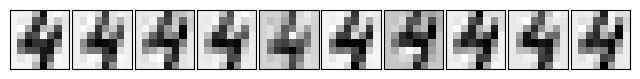

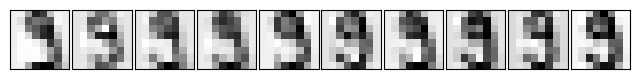

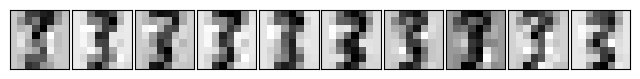

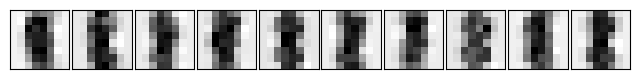

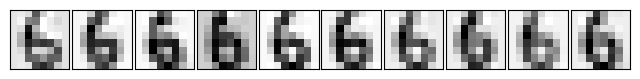

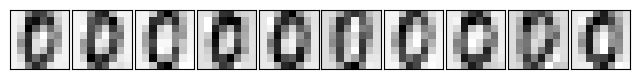

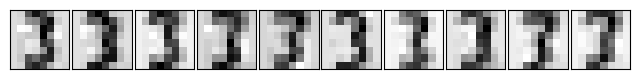

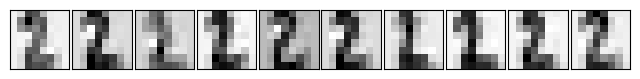

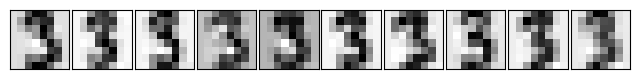

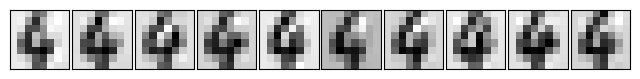

In [20]:
for i in range(10):
    mu = gm.means_[i]
    sigma = gm.covariances_[i]
    new_data = mvn(mu, sigma).rvs(10)
    new_data_in_old_coordinates = pca.inverse_transform(new_data)
    plot_digits(new_data_in_old_coordinates)

So we do see that each mixture component stays within a single class – there are simply several different "zeros". With only 10 mixture components, the model looks worse:

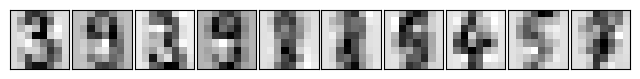

[1 1 1 1 2 2 5 7 8 9]


In [21]:
gm = GaussianMixture(10, random_state=23)
gm.fit(data)

new_data, new_labels = gm.sample(10)
new_data_in_old_coordinates = pca.inverse_transform(new_data)
plot_digits(new_data_in_old_coordinates)
print(new_labels)

To generate, say, a $7$ within our paradigm and without additional algorithms, we can train directly on the subset of the data consisting of the $7$s:

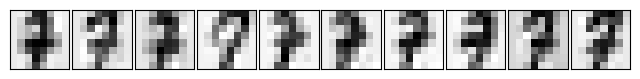

In [22]:
gm7 = GaussianMixture(10, random_state=23)
gm7.fit(data[y == 7])

new_data, new_labels = gm7.sample(10)
new_data_in_old_coordinates = pca.inverse_transform(new_data)
plot_digits(new_data_in_old_coordinates)

### Fashion-MNIST

Simply because we can, let us look at exactly the same thing on the Fashion-MNIST dataset:

In [23]:
from itertools import product
import numpy as np

# The loader sits in fashion_mnist.py (in the folder of these notes) and is used in the
# Expectation Maximization and Model Selection chapters alike. The data are downloaded only
# on the first call and read from the working directory afterwards.
from fashion_mnist import load_mnist

In [24]:
x_train, y_train = load_mnist(kind='train')
#x_test, y_test = load_mnist(kind='t10k')

In [25]:
def show_fashion_image(raw_data, ax):
    im = ax.imshow(raw_data.reshape(28, 28), cmap='binary')
    #im.set_clim(0, 255) # gets computed by matplotlib anyway

Let us see how long PCA.fit and EM (gm.fit) take on this somewhat larger dataset:

In [26]:
vargoal = .90
pca = PCA(vargoal)
%timeit pca.fit(x_train)
pca.fit(x_train)

4.2 s ± 1.22 s per loop (mean ± std. dev. of 7 runs, 1 loop each)


,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",0.9
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SV

In [27]:
print("kept %d of %d dimensions for %2.f%% of variance "
      % (len(pca.components_), x_train.shape[1], 100*vargoal))
fashion_data = pca.transform(x_train)

kept 84 of 784 dimensions for 90% of variance 


In [28]:
%%time
gm = GaussianMixture(50, random_state=23)
gm.fit(fashion_data[y_train == 1])

CPU times: user 4min 36s, sys: 260 ms, total: 4min 36s
Wall time: 21.9 s


,"n_components n_components: int, default=1The number of mixture components.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",23
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


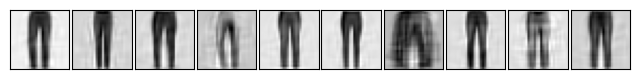

In [29]:
def draw_gm_sample(gm, pca, n=10):
    new_data, new_labels = gm.sample(n)
    new_data_in_old_coordinates = pca.inverse_transform(new_data)

    fig, axs = plt.subplots(1, len(new_data),
                            figsize=(8, 8),
                            subplot_kw=dict(xticks=[],
                                            yticks=[]))
    fig.subplots_adjust(hspace=0.05, wspace=0.05)
    for datapoint, ax in zip(new_data_in_old_coordinates, axs):
        show_fashion_image(datapoint, ax)
    plt.show()

draw_gm_sample(gm, pca, n=10)

In [30]:
%time highres_pca = PCA(.94).fit(x_train)
highres_data = highres_pca.transform(x_train)

CPU times: user 53.8 s, sys: 78.8 ms, total: 53.9 s
Wall time: 4.27 s


CPU times: user 2min 15s, sys: 169 ms, total: 2min 15s
Wall time: 10.9 s


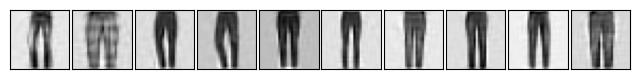

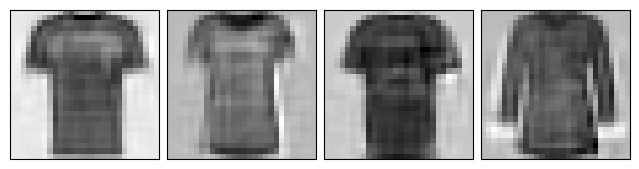

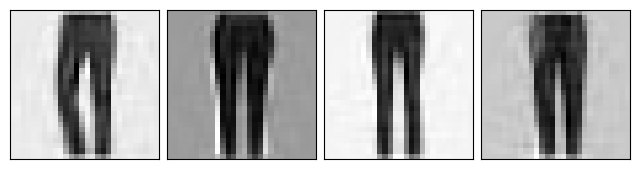

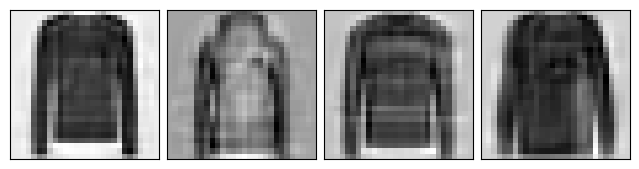

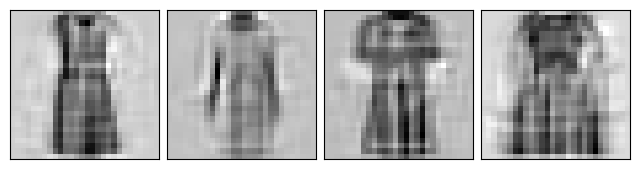

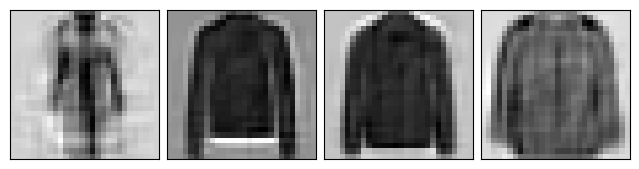

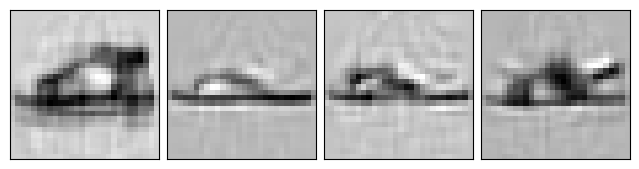

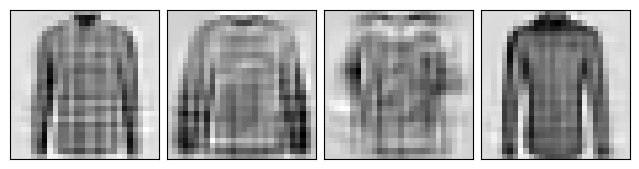

In [31]:
highres_gm = GaussianMixture(90, tol=1e-2, random_state=42)
%time highres_gm.fit(highres_data[y_train == 1])
draw_gm_sample(highres_gm, highres_pca, n=10)
for i in range(7):
    highres_gm.fit(highres_data[y_train == i])
    draw_gm_sample(highres_gm, highres_pca, n=4)

## Looking back and looking ahead

With that, these notes come to an end. The road through the machine learning part of the course was a chain of ideas, each built on the last:

* **k-means** was our first algorithm: measure distances, assign points to centroids, recompute the centroids.
* In the chapter on **statistical models** we recognised k-means as a maximum likelihood estimator and introduced the notions of estimator, bias and likelihood.
* **Principal component analysis** and **linear regression** were the first methods to rest on the covariance matrix and on minimising squared deviations, respectively, with regularisation as the remedy for overfitting.
* The **kernel trick** showed that many of these methods need only distances or inner products and can therefore be carried over to nonlinear structures.
* **Statistical tests** and **model selection** dealt with how to assess results and models without letting the sample fool you: significance, cross-validation, systematic hyperparameter search.
* **Expectation Maximization** closes the circle: a Gaussian mixture model is a 'soft' k-means, one that follows from the maximum likelihood method and Jensen's inequality, and with criteria such as the BIC even the number of components can be chosen on good grounds.

We have deliberately left out, among other things, neural networks and deep learning, time series analysis, reinforcement learning, and everything that comes after the model: deployment, monitoring and the maintenance of models in production. The foundations laid in these notes – probability, expected value, covariance, likelihood, regularisation and validation – turn up again in all of those subjects. The course *Introduction to Deep Learning* follows on directly from these notes; in particular it uses random variables and the expected value, cross-entropy as a loss function, linear regression as the simplest model, Numpy shapes and broadcasting, the train-test split with validation, and the lower bound $L(\theta,q)$ from this chapter, there called the ELBO. Anyone who would like to read further will find the mathematical depth in {cite}`esl` and {cite}`Deisenroth2020`, and the practitioner's perspective in {cite}`dds`.